# Patch latency for zero-day exploits: analysis notebook

TPM020 Deliverable 2, Group 4. Reproduces every number in the Results chapter.

**Files needed next to this notebook**

- `0day _In the Wild_.xlsx`: Project Zero sheet, snapshot of 5 October 2026
- `reserved_dates.csv`: CVE reserved dates, pulled 8 October 2026 (Block 9)
- `cvss_scores.csv`: CVSS v3 scores, pulled 8 October 2026 (Block 15)

**How to run:** Kernel > Restart & Run All. Blocks 9 and 15 are stored as raw cells, so they are skipped and the two CSV snapshots are reused. To pull fresh data, change those cells to Code, but the numbers may then differ from the paper.

**Two latency measures**

- `usable`: discovery-to-patch latency, 132 CVEs
- `res`: reservation-to-patch latency, 403 CVEs

## How to read the output

- **p-value:** how often a result like this would appear if nothing were going on. Below 0.05 counts as significant.
- **Numbers like `1.91e-02`:** scientific notation. `e-02` moves the decimal point two places left, so this is 0.019.
- **adjusted p:** the p-value multiplied by the number of comparisons made in that block (Bonferroni correction). Use this one to decide whether two groups differ.
- **rho and tau:** run from -1 to +1. Zero means no relationship, a negative value means one goes down as the other goes up.
- **H and U:** test statistics for Kruskal-Wallis and Mann-Whitney. The p-value next to them carries the verdict.
- **25%, 50%, 75%:** quartiles. 50% is the median, and 25% to 75% is the middle half of the cases.

## Block 1: Load and clean
Keeps real CVE rows and merges vendor spellings.

In [1]:
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_excel("0day _In the Wild_.xlsx", sheet_name="All")
df = df[df["CVE"].str.startswith("CVE-", na=False)].copy()
df["Vendor"] = df["Vendor"].str.strip().replace({"TrendMicro": "Trend Micro", "Facebook": "Meta"})

print(len(df), "CVEs")
df.head()

410 CVEs


,CVE,Vendor,Product,Type,Description,Date Discovered,Date Patched,Advisory,Analysis URL,Root Cause Analysis,Reported By
0,CVE-2026-85880,Microsoft,Windows,Memory Corruption,Windows Heap-Based Buffer Overflow Vulnerability,???,2026-09-09,https://msrc.microsoft.com/update-guide/vulner...,???,NaN,"Volexity & Mark Kelly, David Galazin and Jerem..."
1,CVE-2026-87491,Google,Chrome,Memory Corruption,V8 Out of Bounds Write Vulnerability,???,2026-09-08,https://chromereleases.googleblog.com/2026/09/...,???,NaN,"Jihyeon Jeong (Compsec Lab, Seoul National Uni..."
2,CVE-2026-85046,Google,Chrome,Memory Corruption,Type confusion in V8,???,2026-09-03,https://chromereleases.googleblog.com/2026/09/...,???,NaN,Salvatore Gulizia (nickname: Serotav)
3,CVE-2026-68820,Microsoft,Windows,Memory Corruption,Windows Ancillary Function Driver for WinSock ...,???,2026-08-11,https://msrc.microsoft.com/update-guide/vulner...,???,NaN,Moshe Marelus and David Driker with Checkpoint
4,CVE-2026-56155,Microsoft,Windows,Feature Bypass,ADFS Elevation of Privilege Vulnerability,???,2026-07-14,https://msrc.microsoft.com/update-guide/vulner...,???,NaN,Jeremy Kingston (DART) and Scott Clark (DART)


**What this shows**

- **What came out:** 410 CVEs.
- **What it means:** this is the full dataset. The sheet also held about 11,700 blank rows and one stray entry, which are removed here. Four rows spelled "Apple " with a trailing space are merged into Apple.

## Block 2: Compute latency
Discovery-to-patch latency in days. Rows without both dates drop out.

In [2]:
start = pd.to_datetime(df["Date Discovered"], format="%Y-%m-%d", errors="coerce")
patch = pd.to_datetime(df["Date Patched"], errors="coerce")
df["latency"] = (patch - start).dt.days
df["year"] = start.dt.year

usable = df[df["latency"] >= 0].copy()
usable["year"] = usable["year"].astype(int)

print(len(usable), "of", len(df), "CVEs have a usable latency")
usable[["CVE", "Vendor", "Date Discovered", "Date Patched", "latency"]].head()

132 of 410 CVEs have a usable latency


,CVE,Vendor,Date Discovered,Date Patched,latency
52,CVE-2024-53197,Google,2024-11-20,2025-04-01,132.0
53,CVE-2024-53150,Google,2024-11-25,2025-04-01,127.0
64,CVE-2024-50302,Google,2024-10-29,2025-03-01,123.0
68,CVE-2024-53104,Google,2024-11-07,2025-02-01,86.0
76,CVE-2024-43047,Qualcomm,2024-07-29,2024-10-07,70.0


**What this shows**

- **What came out:** 132 of 410 CVEs have a usable latency.
- **Why so few:** 277 CVEs have "???" as their discovery date, and one has no patch date.
- **What it means:** only a third of the dataset can be measured this way, and it is not a fair third. Discovery dates exist for 25 of 166 Microsoft CVEs (15%) but 53 of 80 Google CVEs (66%). Results on this measure describe zero-days with a recorded discovery date, not all zero-days.

## Block 3: Descriptive statistics

In [3]:
lat = usable["latency"]

print(lat.describe().round(1))
print("90th percentile:", lat.quantile(0.90))
for days in (7, 30, 90):
    print(f"patched within {days} days: {(lat <= days).mean() * 100:.1f}%")

count    132.0
mean      34.2
std       81.8
min        1.0
25%        3.0
50%        9.0
75%       30.2
max      834.0
Name: latency, dtype: float64
90th percentile: 85.50000000000003
patched within 7 days: 48.5%
patched within 30 days: 75.0%
patched within 90 days: 90.2%


**What this shows**

- **What came out:** median 9 days, mean 34.2 days, middle half between 3 and 30 days, slowest case 834 days. 48.5% are patched within a week and 90.2% within 90 days.
- **What it means:** a typical zero-day with a known discovery date is patched in about nine days. A few take months, which pulls the mean far above the median. That is why the median is the number to report.

## Block 4: Normality check
Shapiro-Wilk. A rejection means the later tests must be rank-based.

Shapiro-Wilk: W = 0.371, p = 2.23e-21
skewness: 7.38


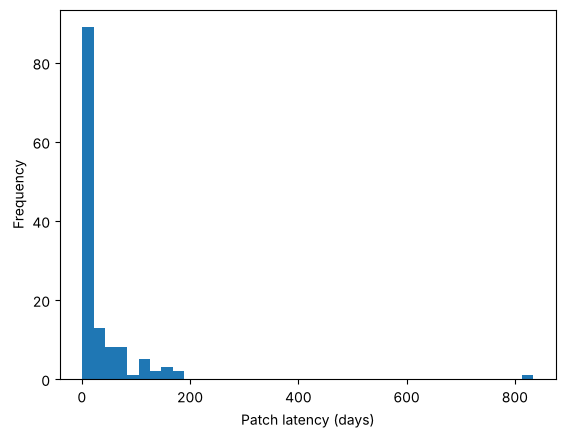

In [4]:
w, p = stats.shapiro(lat)
print(f"Shapiro-Wilk: W = {w:.3f}, p = {p:.2e}")
print(f"skewness: {stats.skew(lat):.2f}")

lat.plot.hist(bins=40)
plt.xlabel("Patch latency (days)")
plt.show()

**What this shows**

- **What came out:** W = 0.371, p < 0.001, skewness 7.38. The histogram has one tall bar on the left and a long tail to the right.
- **What it means:** the data is nowhere near a bell curve (W would be close to 1). Tests that assume a bell curve, such as the t-test and ANOVA, cannot be used. Every test from here on works on ranks instead.

## Block 5: RQ1, time trend (discovery dates)

      count  median
year               
2015     16     9.0
2016     13    10.0
2017      2     9.0
2018      5    34.0
2019      5    10.0
2020     28    14.5
2021     24     6.0
2022     11     3.0
2023     18     9.0
2024     10    37.5
Spearman: rho = -0.043, p = 0.628
Kendall:  tau = -0.026, p = 0.680


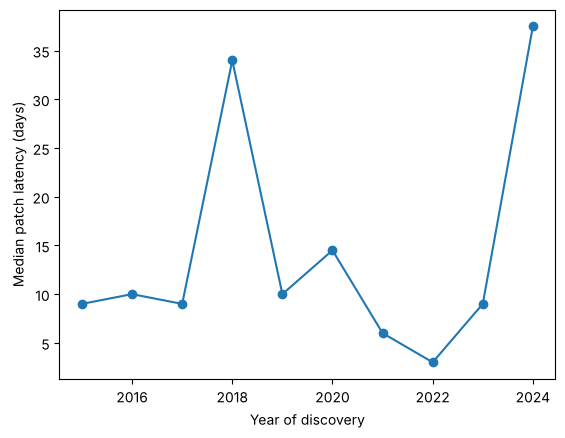

In [5]:
per_year = usable.groupby("year")["latency"].agg(["count", "median"])
print(per_year)

rho, p_rho = stats.spearmanr(usable["year"], usable["latency"])
tau, p_tau = stats.kendalltau(usable["year"], usable["latency"])
print(f"Spearman: rho = {rho:.3f}, p = {p_rho:.3f}")
print(f"Kendall:  tau = {tau:.3f}, p = {p_tau:.3f}")

per_year["median"].plot(marker="o")
plt.xlabel("Year of discovery")
plt.ylabel("Median patch latency (days)")
plt.savefig("median_latency_per_year.png", dpi=150)
plt.show()

**What this shows**

- **What came out:** yearly medians move between 3 and 37.5 days with no direction. Spearman rho = -0.043 (p = 0.63), Kendall tau = -0.026 (p = 0.68).
- **What it means:** there is no sign that latency rose or fell between 2015 and 2024. The hypothesis that latency increases over time is not supported.
- **Caution:** 2017 to 2019 have only 2 to 5 cases each, so a small trend could be hidden.

## Block 6: RQ2, vendor comparison (discovery dates)
Kruskal-Wallis across the four largest vendors, then pairwise Mann-Whitney with Bonferroni correction.

In [6]:
from itertools import combinations

vendors = ["Microsoft", "Google", "Apple", "Adobe"]
top4 = usable[usable["Vendor"].isin(vendors)]
print(top4.groupby("Vendor")["latency"].describe().round(1))

groups = {v: top4.loc[top4["Vendor"] == v, "latency"] for v in vendors}
h, p = stats.kruskal(*groups.values())
print(f"\nKruskal-Wallis: H = {h:.2f}, p = {p:.2e}\n")

pairs = list(combinations(vendors, 2))
for a, b in pairs:
    p_pair = stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided").pvalue
    print(f"{a} vs {b}: p = {p_pair:.2g}, adjusted p = {min(1, p_pair * len(pairs)):.2g}")

           count  mean   std  min   25%   50%   75%    max
Vendor                                                    
Adobe       14.0   8.2   7.8  1.0   4.2   6.0   8.5   29.0
Apple       10.0   9.0   1.4  6.0   9.0   9.5  10.0   10.0
Google      53.0  16.2  33.5  1.0   2.0   4.0   6.0  132.0
Microsoft   25.0  39.6  43.6  5.0  15.0  24.0  48.0  182.0

Kruskal-Wallis: H = 36.68, p = 5.37e-08

Microsoft vs Google: p = 2.8e-07, adjusted p = 1.7e-06
Microsoft vs Apple: p = 0.0002, adjusted p = 0.0012
Microsoft vs Adobe: p = 3.6e-05, adjusted p = 0.00021
Google vs Apple: p = 0.0045, adjusted p = 0.027
Google vs Adobe: p = 0.18, adjusted p = 1
Apple vs Adobe: p = 0.019, adjusted p = 0.12


**What this shows**

- **What came out:** medians of 4 days (Google), 6 (Adobe), 9.5 (Apple) and 24 (Microsoft). Kruskal-Wallis H = 36.68, p < 0.001.
- **Which pairs differ (adjusted p below 0.05):** Microsoft against each of the other three, and Google against Apple. Google vs Adobe and Apple vs Adobe do not differ.
- **What it means:** vendors differ, and Microsoft is the slowest on this measure.
- **Caution:** this is not a ranking of effort. Vendors ship on different release cycles, and Apple's 10 CVEs come from only 4 incidents.

## Block 7: Vendor box plot (discovery dates)

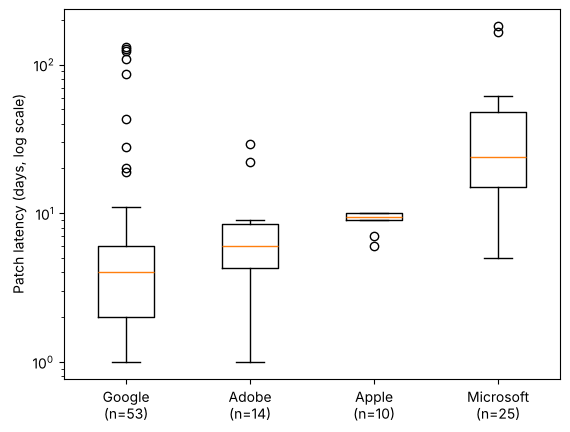

In [7]:
order = sorted(vendors, key=lambda v: groups[v].median())

plt.boxplot([groups[v] for v in order])
plt.xticks(range(1, len(order) + 1), [f"{v}\n(n={len(groups[v])})" for v in order])
plt.yscale("log")
plt.ylabel("Patch latency (days, log scale)")
plt.savefig("latency_by_vendor.png", dpi=150)
plt.show()

**What this shows**

- **What came out:** Microsoft's box sits above the other three. Apple's box is almost a line. Google has a low box with many circles above it.
- **What it means:** the picture agrees with the test in Block 6. The Google circles above 80 days are all Android, which is the first hint that products within a vendor differ.
- **Note:** the axis is logarithmic, so each gridline is ten times the one below.

## Block 8: RQ3, product comparison (discovery dates)
Groups are very small here, so only the Google result carries weight.

In [8]:
products = {
    "Microsoft": ["Windows", "Internet Explorer", "Office"],
    "Google": ["Chrome", "Android"],
    "Apple": ["iOS", "WebKit"],
}

for vendor, names in products.items():
    sub = usable[(usable["Vendor"] == vendor) & usable["Product"].isin(names)]
    print(sub.groupby("Product")["latency"].describe().round(1))
    samples = [sub.loc[sub["Product"] == name, "latency"] for name in names]
    if len(names) == 2:
        result = stats.mannwhitneyu(*samples, alternative="two-sided")
        print(f"{vendor}: Mann-Whitney U = {result.statistic:.1f}, p = {result.pvalue:.2g}\n")
    else:
        result = stats.kruskal(*samples)
        print(f"{vendor}: Kruskal-Wallis H = {result.statistic:.2f}, p = {result.pvalue:.2g}\n")

                   count  mean    std   min   25%   50%   75%    max
Product                                                             
Internet Explorer    3.0  65.3  101.1   5.0   7.0   9.0  95.5  182.0
Office               3.0  63.7   87.8  12.0  13.0  14.0  89.5  165.0
Windows             13.0  33.5   17.6  11.0  19.0  27.0  53.0   61.0
Microsoft: Kruskal-Wallis H = 1.06, p = 0.59

         count  mean   std   min   25%    50%    75%    max
Product                                                    
Android    6.0  97.8  46.1  10.0  91.8  116.0  126.0  132.0
Chrome    47.0   5.8   7.5   1.0   2.0    4.0    6.0   43.0
Google: Mann-Whitney U = 5.0, p = 0.00012

         count  mean  std  min  25%  50%   75%   max
Product                                             
WebKit     2.0   9.5  0.7  9.0  9.2  9.5   9.8  10.0
iOS        8.0   8.9  1.6  6.0  8.5  9.5  10.0  10.0
Apple: Mann-Whitney U = 7.0, p = 0.89



**What this shows**

- **What came out:** Chrome (median 4 days, 47 cases) vs Android (116 days, 6 cases): p < 0.001. Microsoft products: p = 0.59 with groups of 13, 3 and 3. Apple: p = 0.89 with groups of 8 and 2.
- **What it means:** only the Google comparison carries weight. For Microsoft and Apple the groups are too small to detect a difference, so those results are inconclusive. They do not show that the products are the same.

## Block 9: Reserved-date pull (run once)
Raw cell, skipped by Run All. Reads `dateReserved` for every CVE from the CVE List repository and writes `reserved_dates.csv`.

**What this shows**

- **What came out:** a reserved date for all 410 CVEs, saved to `reserved_dates.csv`.
- **What it means:** the reserved date is the day the CVE ID was set aside. It is the candidate stand-in for the missing discovery dates, and Block 10 tests whether it is a good one.

## Block 10: Proxy validation
Compares discovery and reserved dates on the CVEs that have both. `gap` is discovery minus reserved, so a positive value means the ID was reserved first.

In [9]:
dates = pd.read_csv("reserved_dates.csv")
df["Date Reserved"] = df["CVE"].map(dates.set_index("CVE")["Date Reserved"])
reserved = pd.to_datetime(df["Date Reserved"])
df["latency_reserved"] = (patch - reserved).dt.days

gap = (start - reserved).dt.days.dropna()
print(len(gap), "CVEs have both dates")
print(f"mean absolute difference: {gap.abs().mean():.1f} days, SD: {gap.std():.1f}")
print(f"reserved before discovery: {(gap > 0).sum()}, same day: {(gap == 0).sum()}, after: {(gap < 0).sum()}")

rho_dates, _ = stats.spearmanr(start[gap.index].rank(), reserved[gap.index].rank())
both = df.dropna(subset=["latency", "latency_reserved"])
rho_latency, p_latency = stats.spearmanr(both["latency"], both["latency_reserved"])
print(f"Spearman between the two dates:     rho = {rho_dates:.3f}")
print(f"Spearman between the two latencies: rho = {rho_latency:.3f}, p = {p_latency:.2g}")

print(gap.groupby(df["Vendor"]).agg(["count", "median"]).loc[["Microsoft", "Google", "Apple", "Adobe"]])

133 CVEs have both dates
mean absolute difference: 55.7 days, SD: 88.3
reserved before discovery: 83, same day: 1, after: 49
Spearman between the two dates:     rho = 0.994
Spearman between the two latencies: rho = 0.438, p = 1.5e-07
           count  median
Vendor                  
Microsoft     25    79.0
Google        53     6.0
Apple         10     6.0
Adobe         14    31.0


**What this shows**

- **What came out:** 133 CVEs have both dates. They are 55.7 days apart on average. The ID was reserved before discovery in 83 cases, on the same day in 1, and after in 49.
- **The two correlations:** 0.994 between the dates, 0.438 between the latencies. The first is high only because the dates span ten years. The second is the one that matters, and it is moderate.
- **By vendor:** IDs were reserved a median of 79 days before discovery for Microsoft, 31 for Adobe, 6 for Google and 6 for Apple.
- **What it means:** the reserved date is a weak stand-in. It is often set before the flaw is found, probably because vendors reserve IDs in advance. The error also differs by vendor, so it adds far more days to Microsoft than to Google.

## Block 11: Reserved-date dataset
Builds `res`, the reservation-to-patch dataset, with the same column names as `usable`.

In [10]:
res = df[df["latency_reserved"] >= 0].copy()
res["latency"] = res["latency_reserved"]
res["year"] = reserved.dt.year[res.index]

print(len(res), "of", len(df), "CVEs have a usable reserved-date latency")
print((df["latency_reserved"] < 0).sum(), "dropped because the ID was reserved after the patch")

lat_res = res["latency"]
print(lat_res.describe().round(1))
print("90th percentile:", lat_res.quantile(0.90))
for days in (7, 30, 90):
    print(f"patched within {days} days: {(lat_res <= days).mean() * 100:.1f}%")

w, p = stats.shapiro(lat_res)
print(f"Shapiro-Wilk: W = {w:.3f}, p = {p:.2e}")

403 of 410 CVEs have a usable reserved-date latency
6 dropped because the ID was reserved after the patch
count    403.0
mean      80.7
std       77.8
min        0.0
25%       23.5
50%       56.0
75%      114.5
max      426.0
Name: latency, dtype: float64
90th percentile: 186.0
patched within 7 days: 12.9%
patched within 30 days: 28.5%
patched within 90 days: 66.3%
Shapiro-Wilk: W = 0.855, p = 6.99e-19


**What this shows**

- **What came out:** 403 usable CVEs. Six are dropped because the ID was reserved after the patch, and one has no patch date. Median 56 days, middle half 23.5 to 114.5 days, 12.9% patched within a week. Shapiro-Wilk W = 0.855, p < 0.001.
- **What it means:** the sample triples, but the clock is different. This latency includes however long the ID sat reserved before the flaw was found, so it runs much longer than the 9-day median in Block 3. The data is still not bell-shaped, so the same rank-based tests apply.

## Block 12a: RQ1 on reserved dates

      count  median
year               
2013      1   235.0
2014     14    76.0
2015     31   116.0
2016     33   182.0
2017      7    41.0
2018     23   153.0
2019     16   102.5
2020     32    83.5
2021     57    46.0
2022     40    46.0
2023     50    33.0
2024     39    60.0
2025     46    40.0
2026     14     3.0
Spearman: rho = -0.440, p = 1.6e-20
Kendall:  tau = -0.312, p = 5e-19


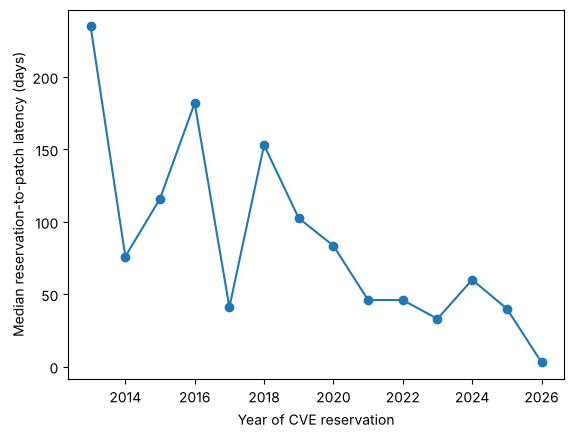

In [11]:
per_year_res = res.groupby("year")["latency"].agg(["count", "median"])
print(per_year_res)

rho, p_rho = stats.spearmanr(res["year"], res["latency"])
tau, p_tau = stats.kendalltau(res["year"], res["latency"])
print(f"Spearman: rho = {rho:.3f}, p = {p_rho:.2g}")
print(f"Kendall:  tau = {tau:.3f}, p = {p_tau:.2g}")

per_year_res["median"].plot(marker="o")
plt.xlabel("Year of CVE reservation")
plt.ylabel("Median reservation-to-patch latency (days)")
plt.savefig("median_latency_per_year_reserved.png", dpi=150)
plt.show()

**What this shows**

- **What came out:** medians above 100 days in 2015, 2016, 2018 and 2019, and between 33 and 60 days from 2021 to 2025. Spearman rho = -0.440, Kendall tau = -0.312, both p < 0.001.
- **What it means:** on this measure latency appears to fall over time, which contradicts Block 5. Block 12b checks which of the two to believe.

## Block 12b: RQ1 check, same CVEs
Runs the trend test on both measures for the CVEs that have both, to see whether the decline in 12a comes from patching or from the proxy.

In [12]:
same = res.loc[res.index.intersection(usable.index)]
checks = {
    "reservation-to-patch latency": same["latency"],
    "discovery-to-patch latency": usable.loc[same.index, "latency"],
    "days reserved before discovery": gap[same.index],
}
print(len(same), "CVEs with both dates")
for label, values in checks.items():
    rho, p = stats.spearmanr(same["year"], values)
    print(f"{label} vs year: rho = {rho:.3f}, p = {p:.2g}")

print(gap[same.index].groupby(same["year"]).agg(["count", "median"]))

130 CVEs with both dates
reservation-to-patch latency vs year: rho = -0.422, p = 5.6e-07
discovery-to-patch latency vs year: rho = 0.003, p = 0.97
days reserved before discovery vs year: rho = -0.552, p = 1e-11
      count  median
year               
2014      3    46.0
2015     16    38.0
2016     10    37.5
2017      2    74.0
2018      8   137.5
2019      4   101.0
2020     22    78.0
2021     25    43.0
2022     12    -2.0
2023     18    -2.0
2024     10    -1.5


**What this shows**

- **What came out:** on the same 130 CVEs, reservation-to-patch latency falls over time (rho = -0.422) while discovery-to-patch latency is flat (rho = 0.003, p = 0.97). The reservation lead shrinks over time (rho = -0.552): a median of 37 to 138 days before discovery up to 2021, and about 2 days after discovery from 2022.
- **What it means:** the decline in 12a comes from the proxy, not from faster patching. IDs used to be reserved weeks before discovery and are now reserved at about the time of discovery, so the measured latency shrank by itself.
- **Conclusion for RQ1:** no evidence of a trend in patching speed under either measure.

## Block 13a: RQ2 on reserved dates

           count  mean   std  min   25%   50%    75%    max
Vendor                                                     
Adobe       28.0  65.9  58.6  5.0  17.2  52.5   95.0  235.0
Apple       64.0  59.7  56.2  4.0  15.8  46.5   91.0  244.0
Google      79.0  61.0  85.8  0.0   1.0  45.0   92.0  426.0
Microsoft  166.0  95.9  76.6  5.0  40.0  62.0  143.8  379.0
Kruskal-Wallis: H = 29.65, p = 1.64e-06
Microsoft vs Google: p = 5.6e-06, adjusted p = 3.4e-05
Microsoft vs Apple: p = 0.00011, adjusted p = 0.00065
Microsoft vs Adobe: p = 0.047, adjusted p = 0.28
Google vs Apple: p = 0.041, adjusted p = 0.25
Google vs Adobe: p = 0.074, adjusted p = 0.45
Apple vs Adobe: p = 0.6, adjusted p = 1


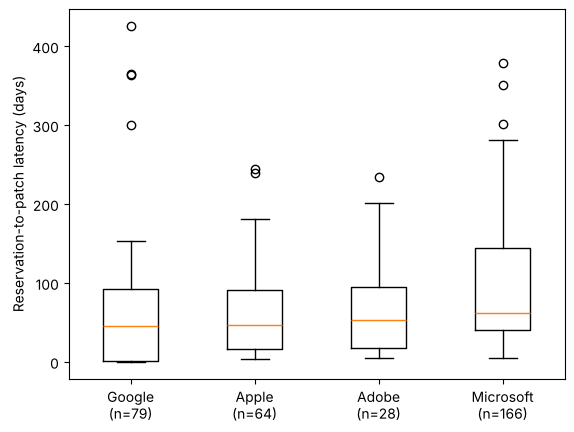

In [13]:
def compare(groups):
    h, p = stats.kruskal(*groups.values())
    print(f"Kruskal-Wallis: H = {h:.2f}, p = {p:.2e}")
    pairs = list(combinations(groups, 2))
    for a, b in pairs:
        p_pair = stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided").pvalue
        print(f"{a} vs {b}: p = {p_pair:.2g}, adjusted p = {min(1, p_pair * len(pairs)):.2g}")

top4_res = res[res["Vendor"].isin(vendors)]
print(top4_res.groupby("Vendor")["latency"].describe().round(1))

groups_res = {v: top4_res.loc[top4_res["Vendor"] == v, "latency"] for v in vendors}
compare(groups_res)

order_res = sorted(vendors, key=lambda v: groups_res[v].median())
plt.boxplot([groups_res[v] for v in order_res])
plt.xticks(range(1, len(order_res) + 1), [f"{v}\n(n={len(groups_res[v])})" for v in order_res])
plt.ylabel("Reservation-to-patch latency (days)")
plt.savefig("latency_by_vendor_reserved.png", dpi=150)
plt.show()

**What this shows**

- **What came out:** medians of 45 days (Google), 46.5 (Apple), 52.5 (Adobe) and 62 (Microsoft). Kruskal-Wallis H = 29.65, p < 0.001. After adjustment, Microsoft differs from Google and from Apple. No other pair differs.
- **What it means:** vendors still differ, but the gaps are much smaller than in Block 6. The reservation lead time is added to every vendor, which pushes the medians together.

## Block 13b: RQ2 check, 2022 onwards
Same comparison on recent reservations only, where the reserved date is close to discovery. Adobe has 2 cases and is left out.

In [14]:
recent = top4_res[top4_res["year"] >= 2022]
print(recent.groupby("Vendor")["latency"].describe().round(1))

groups_recent = {v: recent.loc[recent["Vendor"] == v, "latency"] for v in ["Microsoft", "Google", "Apple"]}
compare(groups_recent)

           count   mean    std   min   25%    50%    75%    max
Vendor                                                         
Adobe        2.0  107.5  133.6  13.0  60.2  107.5  154.8  202.0
Apple       42.0   47.7   43.5   4.0  16.0   40.0   69.0  240.0
Google      50.0   26.4   45.8   0.0   0.0    1.0   20.0  138.0
Microsoft   65.0   47.4   25.2   5.0  33.0   42.0   62.0  147.0
Kruskal-Wallis: H = 30.64, p = 2.22e-07
Microsoft vs Google: p = 5.8e-07, adjusted p = 1.8e-06
Microsoft vs Apple: p = 0.33, adjusted p = 0.98
Google vs Apple: p = 6.6e-06, adjusted p = 2e-05


**What this shows**

- **What came out:** for reservations from 2022 onwards, medians of 1 day (Google, 50 cases), 40 (Apple, 42) and 42 (Microsoft, 65). Kruskal-Wallis H = 30.64, p < 0.001. Google differs from both others. Microsoft and Apple do not differ (adjusted p = 0.98). Adobe appears in the table with 2 cases but is not tested.
- **What it means:** in the period where the reserved date is close to discovery, Google stands apart and Microsoft and Apple look alike.
- **Across Blocks 6, 13a and 13b:** two results hold every time. Vendors differ, and Google is faster than Microsoft. Apple's position changes from view to view, so it should not be ranked.
- **Caution:** the evidence that recent reserved dates track discovery comes mostly from Google CVEs.

## Block 14a: RQ3 on reserved dates
For the two-product vendors, report the pairwise Mann-Whitney line.

In [15]:
for vendor, names in products.items():
    sub = res[(res["Vendor"] == vendor) & res["Product"].isin(names)]
    print(sub.groupby("Product")["latency"].describe().round(1))
    compare({name: sub.loc[sub["Product"] == name, "latency"] for name in names})
    print()

                   count   mean   std   min   25%    50%    75%    max
Product                                                               
Internet Explorer   23.0  150.4  96.5  11.0  81.0  130.0  212.0  351.0
Office              18.0  103.3  76.4  27.0  42.0   66.0  162.8  242.0
Windows             98.0   89.1  72.0   5.0  40.0   60.0  131.5  379.0
Kruskal-Wallis: H = 7.91, p = 1.91e-02
Windows vs Internet Explorer: p = 0.0051, adjusted p = 0.015
Windows vs Office: p = 0.51, adjusted p = 1
Internet Explorer vs Office: p = 0.13, adjusted p = 0.4

         count   mean    std   min   25%    50%    75%    max
Product                                                      
Android   18.0  151.0  124.6  14.0  76.0  115.5  136.8  426.0
Chrome    61.0   34.5   45.1   0.0   0.0    3.0   71.0  153.0
Kruskal-Wallis: H = 22.81, p = 1.79e-06
Chrome vs Android: p = 1.8e-06, adjusted p = 1.8e-06

         count  mean   std  min   25%   50%    75%    max
Product                                     

**What this shows**

- **What came out:** Chrome (median 3 days) vs Android (115.5): p < 0.001. Microsoft products: H = 7.91, p = 0.019, driven by Windows (60 days) vs Internet Explorer (130), adjusted p = 0.015. iOS (22 days) vs WebKit (49): p = 0.49.
- **What it means:** Chrome and Android differ again, as in Block 8. Apple's two products do not differ, and this time the groups are large enough (30 and 27) for that to count. Microsoft's products seem to differ, which Block 14b checks.

## Block 14b: RQ3 check, Microsoft by period
Internet Explorer and Office cases are older than Windows cases, so the comparison is repeated within one period.

In [16]:
ms = res[(res["Vendor"] == "Microsoft") & res["Product"].isin(products["Microsoft"])]
print(ms.groupby("Product")["year"].median())

early = ms[ms["year"] <= 2021]
print(early.groupby("Product")["latency"].agg(["count", "median"]))
compare({name: early.loc[early["Product"] == name, "latency"] for name in products["Microsoft"]})

Product
Internet Explorer    2016.0
Office               2016.0
Windows              2022.0
Name: year, dtype: float64
                   count  median
Product                         
Internet Explorer     22   141.0
Office                14   120.5
Windows               47   124.0
Kruskal-Wallis: H = 0.99, p = 6.09e-01
Windows vs Internet Explorer: p = 0.45, adjusted p = 1
Windows vs Office: p = 0.7, adjusted p = 1
Internet Explorer vs Office: p = 0.35, adjusted p = 1


**What this shows**

- **What came out:** the median reservation year is 2016 for Internet Explorer and Office, and 2022 for Windows. Restricted to reservations up to 2021, the medians are 141, 120.5 and 124 days, with H = 0.99 and p = 0.61.
- **What it means:** the Microsoft difference in 14a was a period effect. Internet Explorer cases are older, and older cases have longer reservation-to-patch latencies (Block 12b). Compared within one period, the products do not differ.
- **Conclusion for RQ3:** a product difference within a vendor is supported for Google only.

## Block 15: CVSS pull (run once)
Raw cell, skipped by Run All. Reads the CVSS v3 base score for every CVE from a public mirror of NVD (`fkie-cad/nvd-json-data-feeds`) and writes `cvss_scores.csv`. NVD's own score is preferred; a vendor or CISA score is used only when NVD has none. If you change this cell to Code, do the same for Block 9, which imports `requests`.

**What this shows**

- **What came out:** a CVSS v3 score for all 410 CVEs, saved to `cvss_scores.csv`. 313 are NVD's own assessment, and 97 come from the vendor or CISA because NVD has not scored those CVEs itself.
- **What it means:** severity is now available for every CVE. The 97 without an NVD assessment are mostly recent.

## Block 16a: RQ4, severity
Bands the scores and tests severity against latency on both measures. Low has one CVE and is left out of the tests.

In [17]:
scores = pd.read_csv("cvss_scores.csv").set_index("CVE")
print(scores["CVSS Source"].value_counts())

band_names = ["Low", "Medium", "High", "Critical"]
severity = pd.cut(scores["CVSS"], bins=[0, 3.9, 6.9, 8.9, 10], labels=band_names).astype(str)
print(severity.value_counts()[band_names])

for name, data in [("Discovery dates", usable), ("Reserved dates", res)]:
    data["CVSS"] = data["CVE"].map(scores["CVSS"])
    data["Severity"] = data["CVE"].map(severity)
    print(f"\n{name}")
    print(data.groupby("Severity")["latency"].describe().round(1).reindex(band_names))
    compare({b: data.loc[data["Severity"] == b, "latency"] for b in ["Medium", "High", "Critical"]})
    rho, p = stats.spearmanr(data["CVSS"], data["latency"])
    print(f"Spearman, score vs latency: rho = {rho:.3f}, p = {p:.2g}")

CVSS Source
NVD      313
other     97
Name: count, dtype: int64
CVSS
Low           1
Medium       48
High        305
Critical     56
Name: count, dtype: int64

Discovery dates
          count   mean    std   min   25%   50%    75%    max
Severity                                                     
Low         1.0   78.0    NaN  78.0  78.0  78.0   78.0   78.0
Medium     21.0  103.1  175.4   2.0  27.0  69.0  121.0  834.0
High       85.0   25.2   39.5   1.0   4.0   9.0   24.0  168.0
Critical   25.0    5.1    4.4   1.0   3.0   4.0    6.0   22.0
Kruskal-Wallis: H = 30.87, p = 1.98e-07
Medium vs High: p = 4.3e-05, adjusted p = 0.00013
Medium vs Critical: p = 4.6e-07, adjusted p = 1.4e-06
High vs Critical: p = 0.0017, adjusted p = 0.0051
Spearman, score vs latency: rho = -0.648, p = 4.4e-17

Reserved dates
          count  mean   std   min   25%   50%    75%    max
Severity                                                   
Low         1.0  39.0   NaN  39.0  39.0  39.0   39.0   39.0
Medium  

**What this shows**

- **What came out:** 1 CVE is Low, 48 Medium, 305 High and 56 Critical.
- **Discovery dates:** medians of 69 days (Medium), 9 (High) and 4 (Critical). H = 30.87, p < 0.001, every pair differs. Spearman rho = -0.648.
- **Reserved dates:** medians of 60, 57 and 25 days. H = 9.33, p = 0.009. Medium and High do not differ. Spearman rho = -0.216.
- **What it means:** more severe vulnerabilities are patched faster, as hypothesised. The link is strong on discovery dates and weak on reserved dates.
- **Caution:** three quarters of the CVEs are High, so severity barely varies. The bands are also tied to vendors: in the discovery set, 8 of the 21 Medium cases are Samsung, and 20 of the 25 Critical cases are Google or Adobe.

## Block 16b: RQ4 check, within vendors
Repeats the severity correlation inside each vendor, to see whether it is more than a vendor difference.

In [18]:
for name, data in [("Discovery dates", usable), ("Reserved dates", res)]:
    print(f"\n{name}")
    for vendor in vendors:
        sub = data[data["Vendor"] == vendor]
        rho, p = stats.spearmanr(sub["CVSS"], sub["latency"])
        print(f"{vendor}: n = {len(sub)}, rho = {rho:.3f}, p = {p:.2g}")


Discovery dates
Microsoft: n = 25, rho = -0.521, p = 0.0076
Google: n = 53, rho = -0.524, p = 5.6e-05
Apple: n = 10, rho = 0.192, p = 0.59
Adobe: n = 14, rho = 0.032, p = 0.91

Reserved dates
Microsoft: n = 166, rho = -0.022, p = 0.78
Google: n = 79, rho = -0.396, p = 0.00031
Apple: n = 64, rho = -0.108, p = 0.39
Adobe: n = 28, rho = -0.084, p = 0.67


**What this shows**

- **What came out:** on discovery dates, the link holds inside Microsoft (rho = -0.521, p = 0.008) and inside Google (rho = -0.524, p < 0.001). Apple and Adobe show nothing, with 10 and 14 cases. On reserved dates, it holds only inside Google (rho = -0.396), and Microsoft shows none (rho = -0.022, p = 0.78).
- **What it means:** on discovery dates the severity link is more than a vendor difference, since it appears within two vendors separately. On reserved dates it survives only for Google, where it reflects Chrome flaws scoring higher and being patched faster than Android flaws.
- **Conclusion for RQ4:** supported in direction, clearly on discovery dates and weakly on reserved dates.

## Summary

**Holds in every view**

- Vendors differ in patch latency.
- Google is faster than Microsoft.
- Chrome is faster than Android.
- Latency does not increase over time.

**Depends on the measure**

- The typical latency: 9 days from discovery, 56 days from reservation.
- Where Apple and Adobe sit among the vendors.
- How strong the link between severity and latency is.

**Produced by the proxy, not by patching**

- The decline over time on reserved dates (Block 12).
- The difference between Microsoft products (Block 14).